In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
from scipy.stats import false_discovery_control, mannwhitneyu, spearmanr

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

tcel = sc.read_h5ad(DIR_PROCESADOS / "04_linfocitos_T.h5ad")
tcel

AnnData object with n_obs × n_vars = 1445 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo', 'leiden_T', 'subtipo_T'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'condicion_colors', 'hvg', 'leiden', 'leiden_T', 'leiden_T_colors', 'leiden_colors', 'log1p', 'muestra_colors', 'neighbors', 'pca', 'rank_genes_groups', 'rank_subtipos', 'scrub

In [2]:
import math

import seaborn as sns

COLORES = {"Sano": "#7a7a7a", "NL": "#5b8db8", "LS": "#c0504d"}
ORDEN = ["Sano", "NL", "LS"]


def boxplot_condicion(ax, datos, y, titulo="", ylabel="", negrita=False, sin_punto=()):
    """Caja sólida por condición con un punto negro por muestra.

    sin_punto: muestras que cuentan para la caja pero cuyo punto se dibuja aparte.
    """
    sns.boxplot(data=datos, x="condicion", y=y, order=ORDEN,
                hue="condicion", hue_order=ORDEN, palette=COLORES, width=0.6,
                showfliers=False, dodge=False, linecolor="black", linewidth=1,
                medianprops={"color": "black", "linewidth": 2}, legend=False, ax=ax)
    puntos = datos[~datos["muestra"].isin(sin_punto)] if sin_punto else datos
    sns.stripplot(data=puntos, x="condicion", y=y, order=ORDEN,
                  color="black", size=4, jitter=0.05, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=10, fontweight="bold" if negrita else "normal")


def rejilla_condicion(largo, panel, y, titulos, ylabel, ncols=3, resaltar=()):
    """Un boxplot por panel. titulos: {panel: texto del título}."""
    nfilas = math.ceil(len(titulos) / ncols)
    fig, axes = plt.subplots(nfilas, ncols, figsize=(3 * ncols, 3 * nfilas), squeeze=False)
    for ax, (nombre, titulo) in zip(axes.flat, titulos.items()):
        boxplot_condicion(ax, largo[largo[panel] == nombre], y, titulo,
                          negrita=nombre in resaltar)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes.flat[len(titulos):]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig

In [3]:
firmas = {
    "TRM": ["CD69", "ITGAE", "CXCR6", "ITGA1", "PDCD1", "CD101", "CRTAM", "RGS1", "ZNF683"],
    "Th1": ["IFNG", "TBX21", "CXCR3", "IL12RB2", "STAT4"],
    "Th2": ["GATA3", "IL4", "IL5", "IL13", "CCR4", "PTGDR2"],
    "Th17": ["RORC", "IL17A", "IL17F", "IL22", "CCR6", "IL23R"],
    "Citotoxicidad": ["GZMA", "GZMB", "GZMK", "PRF1", "NKG7", "GNLY"],
    "Respuesta a IFN": ["STAT1", "IRF1", "GBP1", "GBP2", "GBP4", "GBP5", "IFI6", "ISG15", "MX1"],
}

for nombre, genes in firmas.items():
    presentes = [g for g in genes if g in tcel.var_names]
    faltan = sorted(set(genes) - set(presentes))
    print(f"{nombre}: {len(presentes)} de {len(genes)} genes. Faltan: {faltan}")
    sc.tl.score_genes(tcel, presentes, score_name=nombre, random_state=0)

TRM: 9 de 9 genes. Faltan: []


Th1: 5 de 5 genes. Faltan: []
Th2: 5 de 6 genes. Faltan: ['IL4']
Th17: 3 de 6 genes. Faltan: ['IL17A', 'IL17F', 'IL22']
Citotoxicidad: 6 de 6 genes. Faltan: []
Respuesta a IFN: 9 de 9 genes. Faltan: []


In [4]:
por_muestra = tcel.obs.groupby("muestra", observed=True)[list(firmas)].mean()
por_muestra["condicion"] = tcel.obs.groupby("muestra", observed=True)["condicion"].first()
por_muestra["n_T"] = tcel.obs["muestra"].value_counts()
por_muestra = por_muestra[por_muestra["n_T"] >= 20]
por_muestra.sort_values("condicion").round(3)

,TRM,Th1,Th2,Th17,Citotoxicidad,Respuesta a IFN,condicion,n_T
muestra,,,,,,,,
486_LS,-0.119,-0.021,-0.063,-0.145,0.043,0.202,LS,35
BIO023_LS,0.011,-0.050,-0.140,-0.078,-0.089,0.097,LS,23
DER114_LS,-0.002,-0.107,-0.099,-0.004,-0.086,0.041,LS,298
DER115_LS,-0.088,-0.103,-0.104,-0.018,0.017,0.026,LS,432
DER119_LS,-0.098,-0.115,-0.138,0.111,-0.123,0.049,LS,73
DER114_NL,-0.019,-0.068,-0.096,0.002,0.010,-0.012,NL,101
DER115_NL,0.004,-0.057,-0.106,-0.022,0.106,0.044,NL,200
DER119_NL,-0.118,-0.152,-0.070,0.200,-0.186,-0.005,NL,52
DER120_NL,-0.093,-0.152,-0.126,-0.064,-0.160,-0.000,NL,30


In [5]:
orden = {"Sano": 0, "NL": 1, "LS": 2}
filas = []
for s in firmas:
    g = {c: por_muestra.loc[por_muestra["condicion"] == c, s] for c in orden}
    rho = spearmanr(por_muestra["condicion"].map(orden), por_muestra[s])
    filas.append({"firma": s,
                  "mediana_Sano": g["Sano"].median(),
                  "mediana_NL": g["NL"].median(),
                  "mediana_LS": g["LS"].median(),
                  "p_NL_vs_Sano": mannwhitneyu(g["NL"], g["Sano"]).pvalue,
                  "p_LS_vs_Sano": mannwhitneyu(g["LS"], g["Sano"]).pvalue,
                  "rho_tendencia": rho.statistic,
                  "p_tendencia": rho.pvalue})

res = pd.DataFrame(filas).set_index("firma")
for col in ["p_NL_vs_Sano", "p_LS_vs_Sano", "p_tendencia"]:
    res[col.replace("p_", "q_")] = false_discovery_control(res[col])

res.round(3).to_csv(DIR_TABLAS / "firmas_T_estadistica.csv")
res.round(3)

,mediana_Sano,mediana_NL,mediana_LS,p_NL_vs_Sano,p_LS_vs_Sano,rho_tendencia,p_tendencia,q_NL_vs_Sano,q_LS_vs_Sano,q_tendencia
firma,,,,,,,,,,
TRM,-0.073,-0.056,-0.088,0.730,1.000,0.063,0.831,1.000,1.000,0.831
Th1,-0.113,-0.110,-0.103,1.000,0.548,0.231,0.428,1.000,0.657,0.513
Th2,-0.044,-0.101,-0.104,0.111,0.095,-0.545,0.044,0.667,0.286,0.131
Th17,0.055,-0.010,-0.018,0.905,0.548,-0.231,0.428,1.000,0.657,0.513
Citotoxicidad,-0.197,-0.075,-0.086,0.413,0.421,0.314,0.273,0.825,0.657,0.513
Respuesta a IFN,-0.012,-0.003,0.049,0.413,0.032,0.692,0.006,0.825,0.190,0.037


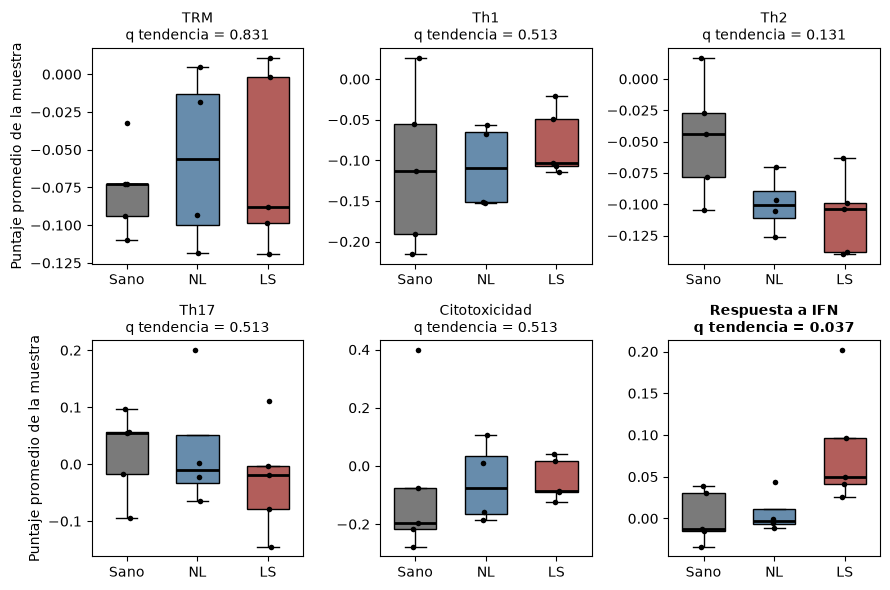

In [6]:
largo = por_muestra.reset_index().melt(id_vars=["muestra", "condicion", "n_T"],
                                       var_name="firma", value_name="puntaje")
titulos = {f: f"{f}\nq tendencia = {res.loc[f, 'q_tendencia']:.3f}" for f in firmas}

fig = rejilla_condicion(largo, "firma", "puntaje", titulos, "Puntaje promedio de la muestra",
                        resaltar=["Respuesta a IFN"])
fig.savefig(DIR_FIGURAS / "firmas_T_por_condicion.png", dpi=300, bbox_inches="tight")

In [7]:
por_muestra.round(4).to_csv(DIR_TABLAS / "firmas_T_por_muestra.csv")

In [8]:
escenarios = {
    "Original": [],
    "Sin CON194": ["CON194"],
    "Sin DER114_LS y DER115_LS": ["DER114_LS", "DER115_LS"],
    "Sin 486_LS y BIO023_LS": ["486_LS", "BIO023_LS"],
}

filas = []
for nombre, excluir in escenarios.items():
    d = por_muestra.drop(index=excluir)
    g = {c: d.loc[d["condicion"] == c, "Respuesta a IFN"] for c in orden}
    rho = spearmanr(d["condicion"].map(orden), d["Respuesta a IFN"])
    filas.append({"escenario": nombre,
                  "n_Sano": len(g["Sano"]), "n_NL": len(g["NL"]), "n_LS": len(g["LS"]),
                  "p_NL_vs_Sano": mannwhitneyu(g["NL"], g["Sano"]).pvalue,
                  "p_LS_vs_Sano": mannwhitneyu(g["LS"], g["Sano"]).pvalue,
                  "rho_tendencia": rho.statistic,
                  "p_tendencia": rho.pvalue})

sens_ifn = pd.DataFrame(filas).set_index("escenario")
sens_ifn.round(3).to_csv(DIR_TABLAS / "sensibilidad_firma_IFN.csv")
sens_ifn.round(3)

,n_Sano,n_NL,n_LS,p_NL_vs_Sano,p_LS_vs_Sano,rho_tendencia,p_tendencia
escenario,,,,,,,
Original,5,4,5,0.413,0.032,0.692,0.006
Sin CON194,4,4,5,0.686,0.063,0.652,0.016
Sin DER114_LS y DER115_LS,5,4,3,0.413,0.036,0.738,0.006
Sin 486_LS y BIO023_LS,5,4,3,0.413,0.143,0.566,0.055


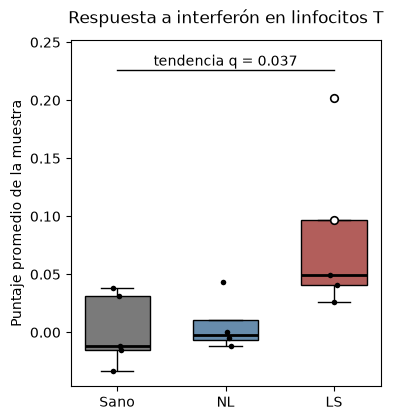

In [9]:
firma = "Respuesta a IFN"
resaltar = ["486_LS", "BIO023_LS"]
datos = por_muestra.reset_index()

fig, ax = plt.subplots(figsize=(4, 4.5))
boxplot_condicion(ax, datos, firma, ylabel="Puntaje promedio de la muestra", sin_punto=resaltar)
ax.scatter([2] * len(resaltar), por_muestra.loc[resaltar, firma], s=30, facecolor="white",
           edgecolor="black", linewidth=1.2, zorder=3)

y_max = por_muestra[firma].max()
ax.plot([0, 2], [y_max * 1.12, y_max * 1.12], color="black", lw=1)
ax.text(1, y_max * 1.14, f"tendencia q = {res.loc[firma, 'q_tendencia']:.3f}", ha="center", fontsize=10)

ax.set_ylim(top=y_max * 1.25)
ax.set_title("Respuesta a interferón en linfocitos T", fontsize=12, pad=12)
fig.savefig(DIR_FIGURAS / "firma_IFN_principal.png", dpi=300, bbox_inches="tight")